# 02 - Frequent Pattern & Association Rule Mining (Task 4-6)

Data: author-based transaction dari `01_preprocessing.ipynb`. Algoritma: Apriori dan FP-Growth (library `mlxtend`).

In [1]:
import time

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

PROCESSED_DIR = '../data/processed'
MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]  # 0,1% 0,5% 1% 2%
MIN_CONF = 0.5

sns.set_theme(style="whitegrid")


def fmt(itemset):
    return ', '.join(sorted(itemset))

## Persiapan data

In [2]:
tx_author = pd.read_pickle(f'{PROCESSED_DIR}/tx_author.pkl')
N = len(tx_author)
print("Jumlah transaksi:", f"{N:,}")
tx_author.head()

Jumlah transaksi: 1,819,240


,author,items,n_items
0,"""johann"" sebastian rudolph","[description logic, theory combination, and al...",1
1,'anau mesui,[ict4d],1
2,'yinka oyerinde,"[conf-irm, ict4d]",2
3,(sophy) shu-jiun chen,[dublin core conference],1
4,2077ai,[neurips],1


Item dengan support < 0,1% (min support terkecil) tidak mungkin masuk frequent itemset mana pun (sifat anti-monoton), jadi dibuang dulu supaya matriks one-hot lebih kecil. Jumlah transaksi tetap N, jadi nilai support tidak berubah.

In [3]:
item_count = tx_author['items'].explode().value_counts()
frequent_items = set(item_count[item_count >= MIN_SUPPORTS[0] * N].index)
print("Item awal            :", len(item_count))
print("Item support >= 0,1% :", len(frequent_items))

transactions = [[i for i in items if i in frequent_items] for items in tx_author['items']]

te = TransactionEncoder()
onehot = pd.DataFrame(te.fit(transactions).transform(transactions), columns=te.columns_)
print("Matriks one-hot      :", onehot.shape)

Item awal            : 4478
Item support >= 0,1% : 587


Matriks one-hot      : (1819240, 587)


## Task 4 - Frequent Pattern Mining

Apriori dijalankan dengan `low_memory=True` karena mode default kehabisan RAM (16 GB) di min support 0,1%. Hasilnya tetap sama.

In [4]:
def run(algo, min_support):
    t0 = time.perf_counter()
    if algo == 'apriori':
        fi = apriori(onehot, min_support=min_support, use_colnames=True, low_memory=True)
    else:
        fi = fpgrowth(onehot, min_support=min_support, use_colnames=True)
    waktu = time.perf_counter() - t0

    fi['k'] = fi['itemsets'].apply(len)
    fi = fi.sort_values('support', ascending=False).reset_index(drop=True)
    return fi, waktu


hasil = {}
for ms in MIN_SUPPORTS:
    for algo in ['apriori', 'fpgrowth']:
        fi, waktu = run(algo, ms)
        hasil[(algo, ms)] = {'itemsets': fi, 'waktu': waktu}
        print(f"{algo:9s} min_support={ms:.1%}  {len(fi):5d} itemsets  {waktu:6.1f} detik")

apriori   min_support=0.1%   1542 itemsets    20.2 detik


fpgrowth  min_support=0.1%   1542 itemsets     9.6 detik


apriori   min_support=0.5%     95 itemsets     4.8 detik


fpgrowth  min_support=0.5%     95 itemsets     5.1 detik


apriori   min_support=1.0%     29 itemsets     2.3 detik


fpgrowth  min_support=1.0%     29 itemsets     4.6 detik


apriori   min_support=2.0%      6 itemsets     0.7 detik


fpgrowth  min_support=2.0%      6 itemsets     4.3 detik


### 4.1 - 4.2 Frequent itemsets per ukuran

Hasil Apriori dan FP-Growth sama persis (dicek di Task 6), jadi yang ditampilkan dari FP-Growth.

In [5]:
rows = []
for ms in MIN_SUPPORTS:
    fi = hasil[('fpgrowth', ms)]['itemsets']
    rows.append({
        'min_support': f'{ms:.1%}',
        'min_jumlah_author': int(np.ceil(ms * N)),
        '1-itemset': (fi['k'] == 1).sum(),
        '2-itemset': (fi['k'] == 2).sum(),
        '3-itemset': (fi['k'] == 3).sum(),
        '>=4-itemset': (fi['k'] >= 4).sum(),
        'total': len(fi),
    })

ringkasan = pd.DataFrame(rows)
ringkasan

,min_support,min_jumlah_author,1-itemset,2-itemset,3-itemset,>=4-itemset,total
0,0.1%,1820,587,396,358,201,1542
1,0.5%,9097,71,22,2,0,95
2,1.0%,18193,28,1,0,0,29
3,2.0%,36385,6,0,0,0,6


In [6]:
# contoh 2-itemset dan 3-itemset di tiap min support (maks 5, urut support)
for ms in MIN_SUPPORTS:
    fi = hasil[('fpgrowth', ms)]['itemsets']
    print(f"min_support {ms:.1%}")
    for k in [2, 3]:
        sub = fi[fi['k'] == k]
        if sub.empty:
            print(f"  {k}-itemset: -")
            continue
        contoh = ' | '.join(fmt(s) for s in sub['itemsets'].head(5))
        lanjut = ' | ...' if len(sub) > 5 else ''
        print(f"  {k}-itemset ({len(sub)}): {contoh}{lanjut}")

min_support 0.1%
  2-itemset (396): icml, neurips | iclr, neurips | cvpr, iccv | aaai, neurips | cvpr, neurips | ...
  3-itemset (358): iclr, icml, neurips | cvpr, eccv, iccv | cvpr, iccv, neurips | aaai, icml, neurips | aaai, iclr, neurips | ...
min_support 0.5%
  2-itemset (22): icml, neurips | iclr, neurips | cvpr, iccv | aaai, neurips | cvpr, neurips | ...
  3-itemset (2): iclr, icml, neurips | cvpr, eccv, iccv
min_support 1.0%
  2-itemset (1): icml, neurips
  3-itemset: -
min_support 2.0%
  2-itemset: -
  3-itemset: -


### 4.3 Top 10 frequent itemsets dengan support tertinggi

In [7]:
for ms in MIN_SUPPORTS:
    top = hasil[('fpgrowth', ms)]['itemsets'].head(10).copy()
    top['itemsets'] = top['itemsets'].apply(fmt)
    top['jumlah_author'] = (top['support'] * N).round().astype(int)
    print(f"=== min_support {ms:.1%} ===")
    display(top[['itemsets', 'k', 'support', 'jumlah_author']])

=== min_support 0.1% ===


,itemsets,k,support,jumlah_author
0,neurips,1,0.031784,57823
1,cvpr,1,0.026186,47638
2,aaai,1,0.025459,46316
3,icassp,1,0.023106,42036
4,embc,1,0.021609,39312
5,hci,1,0.020805,37850
6,emnlp,1,0.019543,35553
7,igarss,1,0.019356,35213
8,acl,1,0.018422,33514
9,iccv,1,0.017685,32173


=== min_support 0.5% ===


,itemsets,k,support,jumlah_author
0,neurips,1,0.031784,57823
1,cvpr,1,0.026186,47638
2,aaai,1,0.025459,46316
3,icassp,1,0.023106,42036
4,embc,1,0.021609,39312
5,hci,1,0.020805,37850
6,emnlp,1,0.019543,35553
7,igarss,1,0.019356,35213
8,acl,1,0.018422,33514
9,iccv,1,0.017685,32173


=== min_support 1.0% ===


,itemsets,k,support,jumlah_author
0,neurips,1,0.031784,57823
1,cvpr,1,0.026186,47638
2,aaai,1,0.025459,46316
3,icassp,1,0.023106,42036
4,embc,1,0.021609,39312
5,hci,1,0.020805,37850
6,emnlp,1,0.019543,35553
7,igarss,1,0.019356,35213
8,acl,1,0.018422,33514
9,iccv,1,0.017685,32173


=== min_support 2.0% ===


,itemsets,k,support,jumlah_author
0,neurips,1,0.031784,57823
1,cvpr,1,0.026186,47638
2,aaai,1,0.025459,46316
3,icassp,1,0.023106,42036
4,embc,1,0.021609,39312
5,hci,1,0.020805,37850


### 4.4 Pengaruh min support terhadap jumlah frequent itemsets

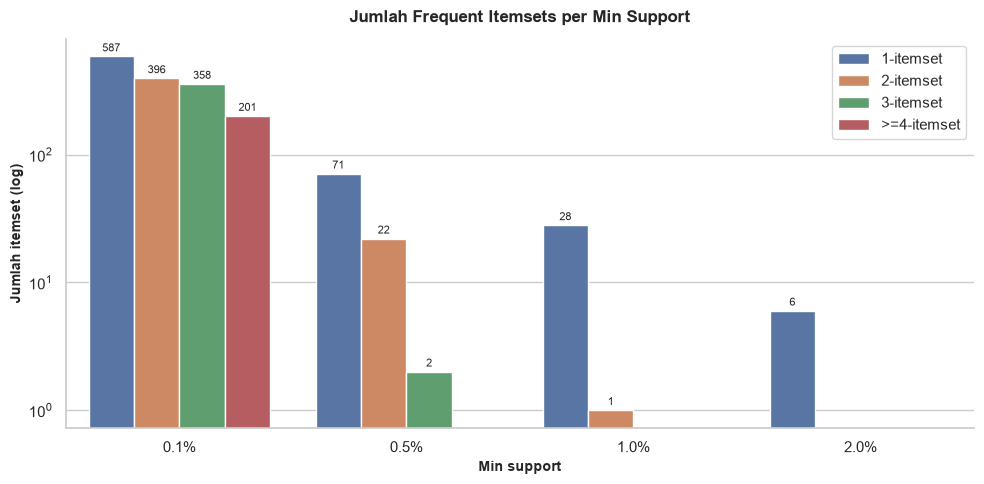

In [8]:
plot_df = ringkasan.melt(
    id_vars='min_support',
    value_vars=['1-itemset', '2-itemset', '3-itemset', '>=4-itemset'],
    var_name='ukuran',
    value_name='jumlah',
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(plot_df, x='min_support', y='jumlah', hue='ukuran', ax=ax)
ax.set_yscale('log')
for container in ax.containers:
    labels = [f"{int(v):,}" if v > 0 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, fontsize=8, padding=2)

ax.set_title("Jumlah Frequent Itemsets per Min Support", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Min support", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah itemset (log)", fontsize=10, fontweight="bold")
ax.legend(title='')
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### 4.5 Kombinasi conference yang paling sering muncul bersama (min support 0,1%)

In [9]:
fi_01 = hasil[('fpgrowth', 0.001)]['itemsets']

top_pairs = {}
for k in [2, 3]:
    top = fi_01[fi_01['k'] == k].head(10).copy()
    top['itemsets'] = top['itemsets'].apply(fmt)
    top['jumlah_author'] = (top['support'] * N).round().astype(int)
    top_pairs[k] = top
    print(f"=== Top 10 {k}-itemset ===")
    display(top[['itemsets', 'support', 'jumlah_author']])

=== Top 10 2-itemset ===


,itemsets,support,jumlah_author
28,"icml, neurips",0.010152,18469
30,"iclr, neurips",0.009843,17907
32,"cvpr, iccv",0.009408,17115
34,"aaai, neurips",0.008764,15943
35,"cvpr, neurips",0.008589,15626
39,"acl, emnlp",0.008404,15289
51,"cvpr, eccv",0.007559,13751
53,"iclr, icml",0.007145,12999
59,"aaai, cvpr",0.006681,12155
61,"icra, iros",0.006520,11862


=== Top 10 3-itemset ===


,itemsets,support,jumlah_author
76,"iclr, icml, neurips",0.005739,10441
93,"cvpr, eccv, iccv",0.005031,9153
99,"cvpr, iccv, neurips",0.004843,8810
128,"aaai, icml, neurips",0.004168,7582
135,"aaai, iclr, neurips",0.004053,7373
137,"aaai, cvpr, neurips",0.004010,7296
140,"cvpr, eccv, neurips",0.003998,7273
144,"cvpr, iclr, neurips",0.003952,7189
150,"aaai, cvpr, iccv",0.003749,6821
165,"eccv, iccv, neurips",0.003451,6279


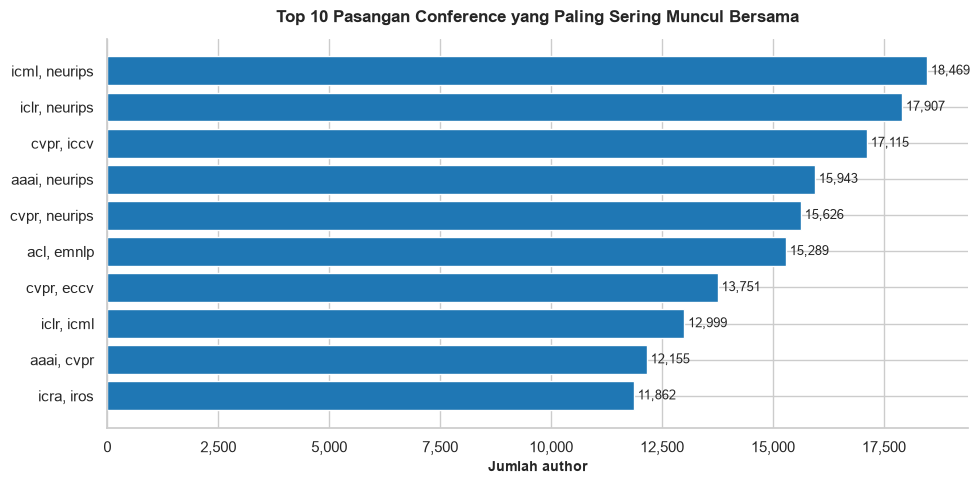

In [10]:
plot_df = top_pairs[2].sort_values('jumlah_author')

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_df['itemsets'], plot_df['jumlah_author'], color="#1f77b4")
ax.bar_label(ax.containers[0], labels=[f" {v:,}" for v in plot_df['jumlah_author']], fontsize=9)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax.set_title("Top 10 Pasangan Conference yang Paling Sering Muncul Bersama", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Jumlah author", fontsize=10, fontweight="bold")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### 4.6 Interpretasi

- Support tiap conference kecil. Yang tertinggi, NeurIPS, cuma 3,18% (57.823 author), karena datanya sangat tersebar: ada 4.478 venue dan 58% author hanya publish di 1 venue. Makanya di min support 2% cuma tersisa 6 conference tanpa satu pun pasangan.
- Makin kecil min support, jumlah itemset naik tajam: 6 (2%), 29 (1%), 95 (0,5%), lalu 1.542 (0,1%). Pasangan pertama baru muncul di 1% ({icml, neurips}) dan 3-itemset di 0,5%.
- Kombinasi paling sering: {icml, neurips} dengan 18.469 author, lalu {iclr, neurips}, {cvpr, iccv}, {aaai, neurips}, dan {acl, emnlp}.
- Polanya mengikuti komunitas riset: machine learning (NeurIPS, ICML, ICLR), computer vision (CVPR, ICCV, ECCV), NLP (ACL, EMNLP), dan robotika (ICRA, IROS). NeurIPS dan AAAI sering muncul bersama conference dari bidang lain, jadi berperan sebagai penghubung antar komunitas.

## Task 5 - Association Rule Mining

Rules dibangkitkan dari frequent itemsets FP-Growth dengan min confidence 50%.

In [11]:
def rapikan(rules):
    out = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].copy()
    out['antecedents'] = out['antecedents'].apply(fmt)
    out['consequents'] = out['consequents'].apply(fmt)
    return out


rules_all = {}
for ms in MIN_SUPPORTS:
    fi = hasil[('fpgrowth', ms)]['itemsets']
    rules_all[ms] = association_rules(fi, num_itemsets=N, metric='confidence', min_threshold=MIN_CONF)
    print(f"min_support {ms:.1%}: {len(rules_all[ms])} rules")

min_support 0.1%: 1388 rules
min_support 0.5%: 10 rules
min_support 1.0%: 1 rules
min_support 2.0%: 0 rules


### 5.1 - 5.2 Association rules beserta support, confidence, dan lift

Maksimal 10 rule per min support, urut dari confidence tertinggi.

In [12]:
for ms in MIN_SUPPORTS:
    print(f"=== min_support {ms:.1%} ({len(rules_all[ms])} rules) ===")
    if rules_all[ms].empty:
        print("tidak ada rule dengan confidence >= 50%")
        continue
    display(rapikan(rules_all[ms]).sort_values('confidence', ascending=False).head(10))

=== min_support 0.1% (1388 rules) ===


,antecedents,consequents,support,confidence,lift
1316,"aaai, acm multimedia, eccv, iccv, neurips",cvpr,0.001017,0.955085,36.473596
1196,"eccv, iccv, neurips, wacv",cvpr,0.001048,0.953477,36.412171
980,"aaai, eccv, iccv, iclr, neurips",cvpr,0.001127,0.949977,36.278514
725,"acm multimedia, eccv, iccv, neurips",cvpr,0.001254,0.941784,35.965626
706,"aaai, eccv, iccv, iclr",cvpr,0.001261,0.939779,35.889062
1225,"eccv, iccv, iclr, icml, neurips",cvpr,0.001040,0.938492,35.839924
1229,"cvpr, eccv, iccv, iclr, icml",neurips,0.001040,0.934321,29.395813
1031,"eccv, iccv, iclr, icml",cvpr,0.001113,0.933610,35.653482
1164,"aaai, eccv, iccv, icml",cvpr,0.001055,0.933366,35.644156
219,"aaai, eccv, iccv, neurips",cvpr,0.001823,0.932527,35.612141


=== min_support 0.5% (10 rules) ===


,antecedents,consequents,support,confidence,lift
9,"eccv, iccv",cvpr,0.005031,0.817670,31.225876
6,"iclr, icml",neurips,0.005739,0.803216,25.270948
7,"cvpr, eccv",iccv,0.005031,0.665624,37.638094
3,eccv,cvpr,0.007559,0.584751,22.330956
5,"iclr, neurips",icml,0.005739,0.583068,33.387075
0,icml,neurips,0.010152,0.581316,18.289502
1,iclr,neurips,0.009843,0.571178,17.970527
4,"icml, neurips",iclr,0.005739,0.565326,32.804794
8,"cvpr, iccv",eccv,0.005031,0.534794,41.372628
2,iccv,cvpr,0.009408,0.531968,20.315234


=== min_support 1.0% (1 rules) ===


,antecedents,consequents,support,confidence,lift
0,icml,neurips,0.010152,0.581316,18.289502


=== min_support 2.0% (0 rules) ===
tidak ada rule dengan confidence >= 50%


**10 rules dengan lift tertinggi (min support 0,1%)**

In [13]:
rules = rules_all[0.001]
rapikan(rules).sort_values('lift', ascending=False).head(10).reset_index(drop=True)

,antecedents,consequents,support,confidence,lift
0,"cvpr, eccv, icml","iccv, iclr, neurips",0.001040,0.514550,166.979980
1,"acm multimedia, eccv, neurips","aaai, cvpr, iccv",0.001017,0.625211,166.751101
2,"eccv, icml, neurips","cvpr, iccv, iclr",0.001040,0.504264,162.944574
3,"cvpr, iccv, icml, neurips","eccv, iclr",0.001040,0.509424,156.812886
4,"eccv, iccv, icml","cvpr, iclr, neurips",0.001040,0.602932,152.577223
5,"cvpr, eccv, icml, neurips","iccv, iclr",0.001040,0.605828,150.607548
6,"acm multimedia, cvpr, iccv, neurips","aaai, eccv",0.001017,0.570635,146.296895
7,"acm multimedia, cvpr, eccv, neurips","aaai, iccv",0.001017,0.698640,138.362150
8,"aaai, eccv, iclr","cvpr, iccv, neurips",0.001127,0.666775,137.687152
9,"cvpr, eccv, icml","iccv, iclr",0.001113,0.550721,136.908051


### 5.3 Hubungan antar-conference yang paling menarik

Top 10 lift di atas semuanya rule panjang dari satu klaster yang sama, jadi untuk melihat hubungan antar conference lebih jelas dipakai rule 1 -> 1.

In [14]:
one_to_one = rules[(rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)]
rapikan(one_to_one).sort_values('lift', ascending=False).head(10).reset_index(drop=True)

,antecedents,consequents,support,confidence,lift
0,ecoc,ofc,0.002490,0.664759,80.026161
1,asru,interspeech,0.001077,0.728083,74.113591
2,esec/sigsoft fse,icse,0.001045,0.516567,73.019386
3,corl,icra,0.001146,0.581473,37.067746
4,acl/ijcnlp,acl,0.001655,0.667998,36.260938
5,spawc,icc,0.001059,0.529557,35.238739
6,acl/ijcnlp,emnlp,0.001678,0.677319,34.658286
7,conference on designing interactive systems,chi,0.001736,0.559313,33.965039
8,eacl,acl,0.001782,0.589809,32.016589
9,eacl,emnlp,0.001828,0.605278,30.971932


In [15]:
# cek arah kebalikannya
sup = dict(zip(fi_01['itemsets'], fi_01['support']))


def conf(x, y):
    return sup.get(frozenset([x, y]), 0) / sup[frozenset([x])]


pairs = [('ecoc', 'ofc'), ('asru', 'interspeech'), ('esec/sigsoft fse', 'icse'), ('corl', 'icra'), ('eacl', 'acl')]
pd.DataFrame([
    {'X': x, 'Y': y, 'conf X -> Y': round(conf(x, y), 3), 'conf Y -> X': round(conf(y, x), 3)}
    for x, y in pairs
])

,X,Y,conf X -> Y,conf Y -> X
0,ecoc,ofc,0.665,0.300
1,asru,interspeech,0.728,0.110
2,esec/sigsoft fse,icse,0.517,0.148
3,corl,icra,0.581,0.073
4,eacl,acl,0.590,0.097


Rule 1 -> 1 dengan lift tertinggi umumnya berbentuk conference kecil/spesialis -> conference utama di bidang yang sama:
- ecoc -> ofc (komunikasi optik), lift 80
- asru -> interspeech (speech), lift 74
- esec/sigsoft fse -> icse (software engineering), lift 73
- corl -> icra (robotika), eacl -> acl (NLP)

Hubungannya satu arah. 73% author ASRU juga publish di Interspeech, tapi cuma 11% author Interspeech yang publish di ASRU.

Top 10 lift keseluruhan (lift 137-167) semuanya ada di klaster CV + ML (cvpr, iccv, eccv, iclr, icml, neurips) dengan support pas di batas 0,1%. Ini kelompok kecil author yang publish di hampir semua conference top AI.

Catatan: rule `acl/ijcnlp -> acl` muncul karena normalisasi venue belum menggabungkan ACL-IJCNLP ke ACL.

### 5.4 Apakah support tinggi selalu menghasilkan lift tinggi?

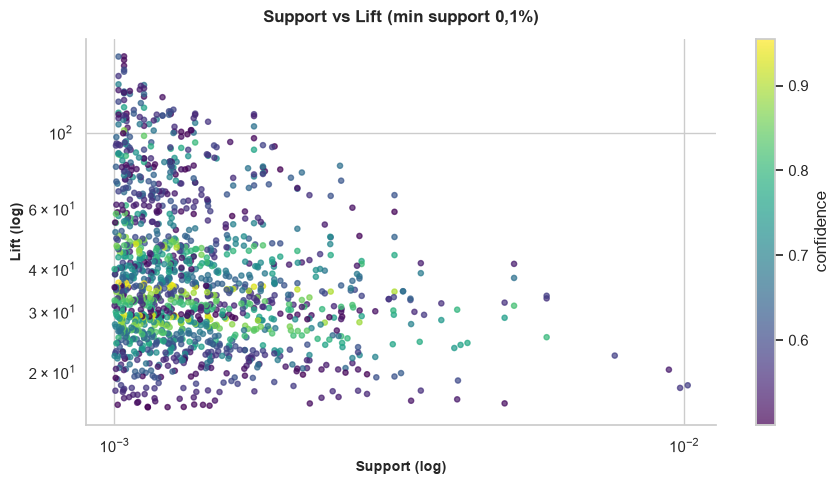

Korelasi Spearman support vs lift: -0.203


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(rules['support'], rules['lift'], c=rules['confidence'], cmap='viridis', s=14, alpha=0.7)
ax.set_xscale('log')
ax.set_yscale('log')
plt.colorbar(sc, label='confidence')
ax.set_title("Support vs Lift (min support 0,1%)", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Support (log)", fontsize=10, fontweight="bold")
ax.set_ylabel("Lift (log)", fontsize=10, fontweight="bold")
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print("Korelasi Spearman support vs lift:", round(rules['support'].corr(rules['lift'], method='spearman'), 3))

In [17]:
# lift = confidence / support(consequent), jadi consequent yang populer cenderung lift-nya kecil
per_consequent = (
    rules[rules['consequents'].apply(len) == 1]
    .assign(consequent=lambda d: d['consequents'].apply(fmt))
    .groupby('consequent')
    .agg(support_consequent=('consequent support', 'first'),
         jumlah_rule=('lift', 'size'),
         median_lift=('lift', 'median'))
    .sort_values('support_consequent', ascending=False)
)
per_consequent.head(10)

,support_consequent,jumlah_rule,median_lift
consequent,,,
neurips,0.031784,234,23.496067
cvpr,0.026186,163,29.955242
aaai,0.025459,189,25.632370
icassp,0.023106,5,22.606306
emnlp,0.019543,53,36.975440
acl,0.018422,51,37.747130
iccv,0.017685,116,38.727777
icml,0.017464,64,33.483152
iclr,0.017233,92,35.346787


In [18]:
# conference besar yang hampir tidak muncul di rules
top10_venue = ['neurips', 'cvpr', 'icassp', 'hci', 'igarss', 'aaai', 'emnlp', 'chi', 'embc', 'acl']  # top 10 publikasi (Task 2)

rows = []
for venue in top10_venue:
    mask = tx_author['items'].apply(lambda items: venue in items)
    rows.append({
        'conference': venue,
        'jumlah_author': mask.sum(),
        'cuma_publish_di_sini': round((tx_author.loc[mask, 'n_items'] == 1).mean(), 3),
        'jadi_consequent': (rules['consequents'] == frozenset([venue])).sum(),
    })

pd.DataFrame(rows).sort_values('cuma_publish_di_sini', ascending=False)

,conference,jumlah_author,cuma_publish_di_sini,jadi_consequent
4,igarss,35213,0.541,0
3,hci,37850,0.407,0
8,embc,39312,0.374,0
7,chi,29958,0.263,1
0,neurips,57823,0.116,234
6,emnlp,35553,0.116,53
9,acl,33514,0.115,51
2,icassp,42036,0.106,5
1,cvpr,47638,0.103,163
5,aaai,46316,0.084,189


Tidak. Korelasi Spearman support vs lift -0,20, dan rule dengan lift tertinggi justru support-nya paling kecil. Consequent paling populer (NeurIPS, CVPR, AAAI, ICASSP) punya median lift paling rendah (23-30), dibanding EMNLP, ACL, dan ICCV (37-39), karena lift = confidence / support(consequent): makin populer consequent-nya, makin kecil lift-nya.

IGARSS, HCI, dan EMBC bahkan tidak pernah jadi consequent. 37-54% author-nya tidak publish di venue lain (NeurIPS, AAAI, CVPR, ACL cuma 8-12%), jadi hampir tidak ada asosiasi dengan conference lain.

### 5.5 Perbedaan support, confidence, dan lift

- **Support**: proporsi author yang publish di semua conference dalam rule. Mengukur seberapa umum polanya.
- **Confidence**: dari author yang publish di X, berapa persen yang juga publish di Y. Punya arah, jadi X -> Y beda dengan Y -> X.
- **Lift**: confidence dibagi support Y, yaitu berapa kali lebih mungkin dibanding author acak. Lift > 1 berarti asosiasi positif, = 1 independen, < 1 negatif.

Contoh: `icml -> neurips` punya support 1,02%, confidence 58%, dan lift 18,3. Artinya 1% author publish di keduanya, 58% author ICML juga publish di NeurIPS, dan peluang itu 18x lebih besar dari peluang author acak publish di NeurIPS (3,2%).

### 5.6 Pola publikasi antar-conference

1. Rules mengelompok per bidang: ML, computer vision, NLP, speech, robotika, komunikasi, software engineering, dan HCI. Rule lintas bidang jarang, kecuali antara CV dan ML.
2. Arahnya dari conference spesialis ke conference utama di bidangnya, tidak sebaliknya.
3. CV dan ML sangat tumpang tindih: 858 dari 1.388 rule punya consequent NeurIPS, CVPR, AAAI, ICCV, ICLR, atau ICML.
4. Conference besar tapi komunitasnya tertutup (IGARSS, HCI, EMBC) hampir tidak membentuk rule.

## Task 6 - Algorithm Performance Comparison

In [19]:
perf = []
for (algo, ms), h in hasil.items():
    fi = h['itemsets']
    n_rules = len(association_rules(fi, num_itemsets=N, metric='confidence', min_threshold=MIN_CONF))
    perf.append({
        'min_support': f'{ms:.1%}',
        'algoritma': algo,
        'waktu_detik': round(h['waktu'], 2),
        'n_itemsets': len(fi),
        'n_rules': n_rules,
    })
perf = pd.DataFrame(perf)

tabel = perf.pivot(index='min_support', columns='algoritma', values=['n_itemsets', 'n_rules', 'waktu_detik'])
tabel['n_itemsets'] = tabel['n_itemsets'].astype(int)
tabel['n_rules'] = tabel['n_rules'].astype(int)
tabel

n_itemsets          n_rules          waktu_detik         
algoritma      apriori fpgrowth apriori fpgrowth     apriori fpgrowth
min_support                                                          
0.1%              1542     1542    1388     1388       20.15     9.63
0.5%                95       95      10       10        4.82     5.12
1.0%                29       29       1        1        2.33     4.63
2.0%                 6        6       0        0        0.72     4.33

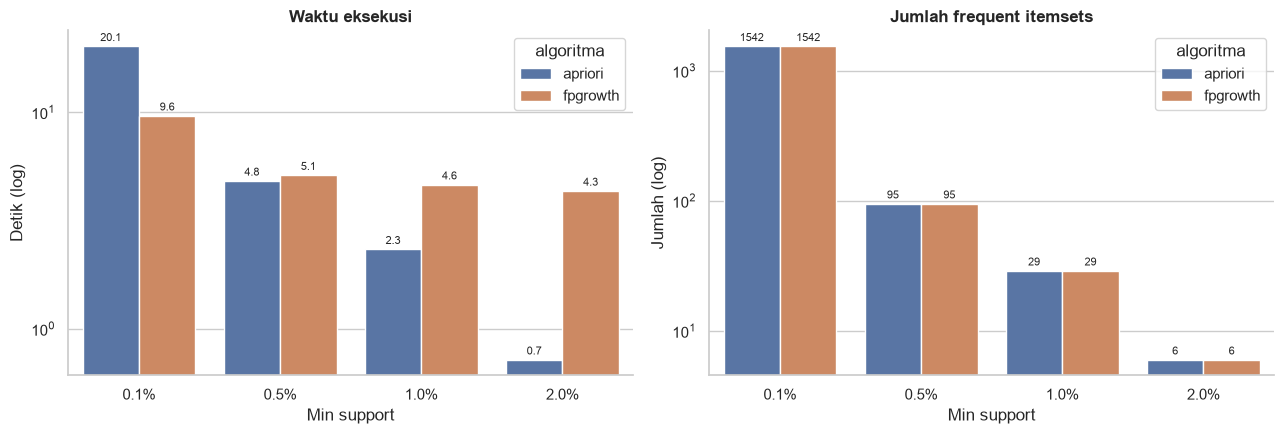

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(perf, x='min_support', y='waktu_detik', hue='algoritma', ax=ax[0])
ax[0].set_title("Waktu eksekusi", fontsize=12, fontweight="bold")
ax[0].set_ylabel("Detik (log)")
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.1f', fontsize=8, padding=2)

sns.barplot(perf, x='min_support', y='n_itemsets', hue='algoritma', ax=ax[1])
ax[1].set_title("Jumlah frequent itemsets", fontsize=12, fontweight="bold")
ax[1].set_ylabel("Jumlah (log)")
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%d', fontsize=8, padding=2)

for a in ax:
    a.set_yscale('log')
    a.set_xlabel("Min support")
    sns.despine(ax=a, top=True, right=True)
plt.tight_layout()
plt.show()

In [21]:
# apakah itemset dan support-nya sama?
for ms in MIN_SUPPORTS:
    a = hasil[('apriori', ms)]['itemsets']
    f = hasil[('fpgrowth', ms)]['itemsets']
    sup_a = dict(zip(a['itemsets'], a['support']))
    sup_f = dict(zip(f['itemsets'], f['support']))

    sama = sup_a.keys() == sup_f.keys() and all(np.isclose(sup_a[i], sup_f[i]) for i in sup_a)
    print(f"min_support {ms:.1%}: apriori={len(sup_a):5d}  fpgrowth={len(sup_f):5d}  ->  {'SAMA' if sama else 'BEDA'}")

min_support 0.1%: apriori= 1542  fpgrowth= 1542  ->  SAMA
min_support 0.5%: apriori=   95  fpgrowth=   95  ->  SAMA
min_support 1.0%: apriori=   29  fpgrowth=   29  ->  SAMA
min_support 2.0%: apriori=    6  fpgrowth=    6  ->  SAMA


### Jawaban

Waktu eksekusi dari satu kali run, jadi angkanya bisa sedikit beda tiap dijalankan.

**1. Bagaimana perubahan min support memengaruhi performa kedua algoritma?**

Makin kecil min support, jumlah itemset (6 -> 1.542), rule (0 -> 1.388), dan waktu eksekusi makin besar. Waktu Apriori naik jauh lebih tajam (sekitar 0,7 -> 20 detik) dibanding FP-Growth (sekitar 4 -> 10 detik). Di min support >= 0,5% Apriori sedikit lebih cepat karena kandidatnya sedikit, sedangkan FP-Growth selalu butuh sekitar 4 detik untuk membangun FP-tree. Di 0,1% FP-Growth sekitar 2x lebih cepat. Apriori mode default juga kehabisan memori di 0,1%.

**2. Apakah kedua algoritma menghasilkan frequent itemsets yang sama?**

Ya. Itemset dan support-nya identik di semua min support, jadi jumlah rule juga sama. Keduanya algoritma exact, bedanya hanya cara mencari (candidate generation vs FP-tree).

**3. Algoritma mana yang lebih sesuai untuk dataset DBLP?**

FP-Growth. Data DBLP besar (1,8 juta transaksi) dan sangat sparse, jadi pola yang menarik baru muncul di min support rendah. Di kondisi itu FP-Growth lebih cepat dan lebih hemat memori. Apriori cuma unggul di min support tinggi, tapi di sana hasilnya hampir tidak informatif (95 itemset dan 10 rule di 0,5%).

## Referensi

- Agrawal, R., Imieliński, T., & Swami, A. (1993). Mining association rules between sets of items in large databases. *Proceedings of ACM SIGMOD*, 207-216.
- Agrawal, R., & Srikant, R. (1994). Fast algorithms for mining association rules. *Proceedings of VLDB*, 487-499.
- Han, J., Pei, J., & Yin, Y. (2000). Mining frequent patterns without candidate generation. *Proceedings of ACM SIGMOD*, 1-12.
- Brin, S., Motwani, R., Ullman, J. D., & Tsur, S. (1997). Dynamic itemset counting and implication rules for market basket data. *Proceedings of ACM SIGMOD*, 255-264.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638.
- Han, J., Kamber, M., & Pei, J. (2011). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann.